# Kazakh Profanity Detection

DSSC5113 Algorithms of Computer Vision · Bonus project · **Author:** Kalashnikova Viktoriya · **Student ID:** 25MD0173

This notebook runs the whole project end to end: data → preprocessing → model → training → one evaluation on the test set → predictions on new comments.

- **Task:** read one Kazakh review or comment and predict `1` if it contains profanity, `0` otherwise.
- **Model:** a character-level CNN trained from scratch (68k parameters, about one minute on a CPU).
- **Data:** real reviews from KazSAnDRA (ISSAI, CC BY 4.0) with my own profanity labels. See the README for the labeling rules and the privacy review.

**How to run**

- *Locally:* open this notebook in the repository root, `pip install -r requirements.txt`, then **Kernel → Restart & Run All**.
- *Google Colab:* put your repository URL into `REPO_URL` in the first code cell, then **Runtime → Run all**. The cell clones the repository and installs the pinned packages.

Everything runs on the CPU. With the pinned package versions the run is deterministic: it reproduces the saved model in `artifacts/` byte for byte.

## 0. Setup

In [1]:
import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/<your-username>/kazakh-profanity-detection.git"   # used only in Colab

if not Path("data/labeled.csv").exists():          # not inside the repository yet -> Colab
    if not Path("kazakh-profanity-detection").exists():
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir("kazakh-profanity-detection")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

print("working directory:", Path.cwd())

working directory: /home/claude/kazakh-profanity-detection


In [2]:
import json, random, re, time, unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold

pd.set_option("display.max_colwidth", 90)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| device: cpu")

CFG = json.loads(Path("configs/train.json").read_text())   # all training settings in one place
CFG

python 3.13.18 | torch 2.15.0+cu132 | numpy 2.5.3 | pandas 3.0.5 | device: cpu


{'seed': 42,
 'max_len': 300,
 'min_char_freq': 2,
 'emb_dim': 48,
 'num_filters': 96,
 'kernel_sizes': [3, 4, 5],
 'dropout': 0.3,
 'batch_size': 64,
 'lr': 0.002,
 'weight_decay': 0.0001,
 'max_epochs': 30,
 'patience': 5}

## 1. Data

`data/labeled.csv` is the public labeled dataset: 3,058 KazSAnDRA comments with my labels, already privacy-cleaned (names of private people replaced by `[NAME]`, 3 comments removed). The column `kazsandra_id` keeps the original KazSAnDRA id, so every text can be traced back to the source.

In [3]:
labeled = pd.read_csv("data/labeled.csv")
DOMAIN = {"pla": "appstore", "kas": "market", "fli": "market", "gis": "mapping", "map": "mapping", "kit": "bookstore"}
labeled["domain"] = labeled["kazsandra_id"].str[:3].map(DOMAIN)

print("rows:", len(labeled))
pd.crosstab(labeled["domain"], labeled["label"], margins=True)

rows: 3058


label,0,1,All
domain,,,
appstore,1202,1519,2721
bookstore,45,6,51
mapping,85,10,95
market,189,2,191
All,1521,1537,3058


Almost all profane comments are app-store reviews (reviews of apps and games, i.e. digital products). Marketplace reviews are moderated and contain almost no profanity, so they mainly add ordinary product-review language to the clean class.

A few labeled examples:

In [4]:
examples = ["Қызмет көрсету өте нашар", "х@кер", "Котакбас ойын", "к*т приложения", "жарнама заебал", "Boq ekengoy"]
for e in examples:
    r = labeled[labeled["text"].str.contains(e, regex=False)].iloc[0]
    print(r["label"], "|", r["text"][:90])
r = labeled[labeled["text"] == "Боқтама"].iloc[0]       # "don't swear": talks about swearing -> 0
print(r["label"], "|", r["text"])

0 | Қызмет көрсету өте нашар. Coll center 10 минут өткен соң жауап берді jusan қосымша сы қате
0 | Мен сіздерге айтып қоямын!!!😱 1.Осы ойында No players online деген ойын бар ғой, содан сол
1 | Котакбас ойын
1 | Қысқасаын айтқанда к*т приложения екен дұрыс істемейді
1 | жарнама заебал болды
1 | Boq ekengoy
0 | Боқтама


### 1.1 Deduplicate, group near-duplicates, split

1. **Exact duplicates** after normalization (lowercase, no punctuation/emoji/digits, long letter runs shortened) are dropped.
2. **Near-duplicates** (character 3–5-gram TF-IDF cosine ≥ 0.9, e.g. `пиздец ойын` / `Пиздец ойын ғо`) are grouped, so each group lands in **one** split. Otherwise the model could see almost the same comment in train and test, and the test score would be too optimistic.
3. **Split 80 / 10 / 10** with `StratifiedGroupKFold`: stratified by label, grouped by near-duplicate group, seed 42.
4. **Label fixes** from `data/label_corrections.csv` (two obscene comments that were labeled 0 by mistake) are applied *after* the split, so the split stays the same as with the original labels.

In [5]:
SEED = CFG["seed"]
NEAR_DUP_THRESHOLD = 0.9

def dedup_key(text):
    t = unicodedata.normalize("NFKC", text).lower()
    t = re.sub(r"[^\w\s]|_|\d", " ", t)          # drop punctuation, emoji, digits
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)         # "керемееет" -> "керемеет"
    return re.sub(r"\s+", " ", t).strip()

def near_duplicate_groups(keys, threshold):
    # union-find over pairs whose char n-gram cosine similarity >= threshold
    X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit_transform(keys.replace("", "<empty>"))
    S = cosine_similarity(X, dense_output=False).tocoo()
    parent = list(range(len(keys)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for a, b, s in zip(S.row, S.col, S.data):
        if a < b and s >= threshold:
            parent[find(a)] = find(b)
    return np.array([find(i) for i in range(len(keys))])

df = pd.read_csv("data/labeled.csv")
df["key"] = df["text"].map(dedup_key)
n_before = len(df)
df = df.drop_duplicates(subset="key", keep="first").reset_index(drop=True)
print("exact duplicates removed:", n_before - len(df))

df["group"] = near_duplicate_groups(df["key"], NEAR_DUP_THRESHOLD)
print("near-duplicate groups with 2+ comments:", int((df["group"].value_counts() > 1).sum()))

sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = list(sgkf.split(df, df["label"], groups=df["group"]))
df["split"] = "train"
df.loc[folds[0][1], "split"] = "test"
df.loc[folds[1][1], "split"] = "val"
assert (df.groupby("group")["split"].nunique() == 1).all()   # no group crosses splits

fixes = pd.read_csv("data/label_corrections.csv")
for row in fixes.itertuples():
    mask = df["kazsandra_id"] == row.kazsandra_id
    assert mask.sum() == 1 and (df.loc[mask, "label"] == row.old_label).all()
    df.loc[mask, "label"] = row.new_label
print("label corrections applied:", len(fixes))

Path("data/processed").mkdir(parents=True, exist_ok=True)
for name in ["train", "val", "test"]:
    df[df["split"] == name][["kazsandra_id", "text", "label"]].to_csv(f"data/processed/{name}.csv", index=False)

train_df, val_df, test_df = (pd.read_csv(f"data/processed/{s}.csv") for s in ["train", "val", "test"])
pd.DataFrame({s: d["label"].value_counts().sort_index() for s, d in
              [("train", train_df), ("val", val_df), ("test", test_df)]}).T.assign(total=lambda t: t.sum(axis=1))

exact duplicates removed: 6


near-duplicate groups with 2+ comments: 16


label corrections applied: 2


label,0,1,total
train,1214,1228,2442
val,152,153,305
test,152,153,305


## 2. Preprocessing: from raw text to character ids

The model reads **characters**, not words. Profanity here comes in many forms: masked (`к*т`), stretched (`бляяя`), misspelled (`зайбал`), Latin (`Boq`), glued to other words (`котакбас`), in two languages. A word-level model would see most of them as unknown words; at character level they share pieces like `кот`, `бля`.

- `normalize`: NFKC, lowercase, letter runs longer than 2 cut to 2, digits → `0`, spaces collapsed. Punctuation like `*` and `@` is **kept**: it marks masked words.
- `clip`: comments longer than 300 characters (3.6% of training) keep the first and last 150 characters.
- `Vocab`: characters seen at least twice **in the training split**; rarer characters map to `<unk>`, padding is `<pad>` = 0.

In [6]:
PAD, UNK = "<pad>", "<unk>"
PAD_ID, UNK_ID = 0, 1

def normalize(text):
    t = unicodedata.normalize("NFKC", str(text)).lower()
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)
    t = re.sub(r"\d", "0", t)
    return re.sub(r"\s+", " ", t).strip()

def clip(text, max_len):
    if len(text) <= max_len:
        return text
    half = max_len // 2
    return text[:half] + text[-(max_len - half):]

class Vocab:
    def __init__(self, chars):
        self.itos = [PAD, UNK] + list(chars)
        self.stoi = {c: i for i, c in enumerate(self.itos)}

    @classmethod
    def build(cls, texts, min_freq=2):
        counts = Counter(ch for t in texts for ch in normalize(t))
        return cls(sorted(c for c, n in counts.items() if n >= min_freq))

    def encode(self, text, max_len):
        t = clip(normalize(text), max_len)
        ids = [self.stoi.get(ch, UNK_ID) for ch in t]
        return ids + [PAD_ID] * (max_len - len(ids))

    def __len__(self):
        return len(self.itos)

vocab = Vocab.build(train_df["text"], min_freq=CFG["min_char_freq"])   # training split only
print("vocabulary size:", len(vocab))

sample = "Котакбас ОЙЫН!!!"
ids = vocab.encode(sample, CFG["max_len"])
print("raw:       ", repr(sample))
print("normalized:", repr(normalize(sample)))
print("first ids: ", ids[:20], "...  length", len(ids))

vocabulary size: 249
raw:        'Котакбас ОЙЫН!!!'
normalized: 'котакбас ойын!!'
first ids:  [84, 88, 92, 74, 84, 75, 74, 91, 2, 88, 83, 101, 87, 3, 3, 0, 0, 0, 0, 0] ...  length 300


## 3. Model: character CNN

```
ids (B, 300) → Embedding (B, 300, 48) → Conv1d k=3,4,5 × 96 filters + ReLU
            → max over positions → concat (B, 288) → dropout 0.3 → Linear → logits (B, 2)
```

Each filter learns to fire on a short character pattern (a swear-word stem, a masked variant). **Max-pooling over positions** keeps its strongest match anywhere in the comment. That matches the label: a comment is profane if a profane fragment appears *anywhere*. Padding positions are masked so they can never win the max.

In [7]:
class CharCNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=48, num_filters=96, kernel_sizes=(3, 4, 5), dropout=0.3, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, num_filters, kernel_size=k, padding=k // 2)
                                    for k in kernel_sizes])
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), num_classes)

    def forward(self, ids):
        x = self.embedding(ids).transpose(1, 2)            # (B, E, L)
        mask = (ids != PAD_ID).unsqueeze(1)                # (B, 1, L)
        pooled = []
        for conv in self.convs:
            h = torch.relu(conv(x))[:, :, : ids.size(1)]   # (B, F, L)
            h = h.masked_fill(~mask, 0.0)                  # padding cannot win the max
            pooled.append(h.max(dim=2).values)             # (B, F)
        return self.fc(self.dropout(torch.cat(pooled, dim=1)))   # (B, 2) raw logits

def build_model():
    return CharCNN(len(vocab), CFG["emb_dim"], CFG["num_filters"], tuple(CFG["kernel_sizes"]), CFG["dropout"])

# shape trace for one comment (untrained model, only to show the shapes)
torch.manual_seed(0)
m = build_model().eval()
x = torch.tensor([ids])
e = m.embedding(x).transpose(1, 2)
h = torch.relu(m.convs[0](e))[:, :, :x.size(1)]
print("ids", tuple(x.shape), "| embedding (transposed)", tuple(e.shape), "| conv k=3", tuple(h.shape),
      "| pooled", tuple(h.max(2).values.shape), "| logits", tuple(m(x).shape))
print("trainable parameters:", sum(p.numel() for p in m.parameters() if p.requires_grad))

ids (1, 300) | embedding (transposed) (1, 48, 300) | conv k=3 (1, 96, 300) | pooled (1, 96) | logits (1, 2)
trainable parameters: 68114


## 4. Training

- Loss: cross-entropy on 2 logits. Optimizer: AdamW, lr 0.002, weight decay 1e-4, batch 64.
- **Early stopping** on validation F1 of the profanity class (patience 5); the best epoch is saved.
- **Decision threshold** chosen on validation to maximize F1.
- The **test set is not used here.**

In [8]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

def encode_df(d):
    X = torch.tensor([vocab.encode(t, CFG["max_len"]) for t in d["text"]], dtype=torch.long)
    return X, torch.tensor(d["label"].values, dtype=torch.long)

@torch.no_grad()
def predict_proba(model, X, batch_size=256):
    model.eval()
    return torch.cat([torch.softmax(model(X[i:i + batch_size]), 1)[:, 1]
                      for i in range(0, len(X), batch_size)]).numpy()

def f1_at(probs, y, threshold):
    pred = probs >= threshold
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return 2 * p * r / (p + r) if p + r else 0.0

set_seed(CFG["seed"])
Xtr, ytr = encode_df(train_df)
Xva, yva = encode_df(val_df)
model = build_model()
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
loss_fn = nn.CrossEntropyLoss()
gen = torch.Generator().manual_seed(CFG["seed"])
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

best_f1, best_epoch, bad_epochs, log = -1.0, 0, 0, []
t0 = time.time()
for epoch in range(1, CFG["max_epochs"] + 1):
    model.train()
    perm = torch.randperm(len(Xtr), generator=gen)
    total = 0.0
    for i in range(0, len(perm), CFG["batch_size"]):
        b = perm[i:i + CFG["batch_size"]]
        opt.zero_grad()
        loss = loss_fn(model(Xtr[b]), ytr[b])
        loss.backward()
        opt.step()
        total += loss.item() * len(b)

    p_val = predict_proba(model, Xva)
    with torch.no_grad():
        model.eval(); val_loss = loss_fn(model(Xva), yva).item()
    val_f1 = f1_at(p_val, yva.numpy(), 0.5)
    log.append({"epoch": epoch, "train_loss": total / len(Xtr), "val_loss": val_loss, "val_f1@0.5": val_f1})
    print(f"epoch {epoch:2d}  train loss {total / len(Xtr):.4f}  val loss {val_loss:.4f}  val F1@0.5 {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1, best_epoch, bad_epochs = val_f1, epoch, 0
        torch.save(model.state_dict(), ART / "model.pt")
    else:
        bad_epochs += 1
        if bad_epochs >= CFG["patience"]:
            print(f"early stopping: no val F1 improvement for {CFG['patience']} epochs")
            break

model.load_state_dict(torch.load(ART / "model.pt", weights_only=True))
p_val = predict_proba(model, Xva)
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
f1s = [f1_at(p_val, yva.numpy(), t) for t in grid]
THRESHOLD = float(grid[int(np.argmax(f1s))])
print(f"\nbest epoch {best_epoch} | val F1@0.5 {best_f1:.4f} | threshold {THRESHOLD} (val F1 {max(f1s):.4f}) | {time.time() - t0:.0f}s")

epoch  1  train loss 0.5542  val loss 0.3618  val F1@0.5 0.8459


epoch  2  train loss 0.3783  val loss 0.3890  val F1@0.5 0.8268


epoch  3  train loss 0.3330  val loss 0.2756  val F1@0.5 0.9130


epoch  4  train loss 0.2450  val loss 0.3082  val F1@0.5 0.8765


epoch  5  train loss 0.2178  val loss 0.2175  val F1@0.5 0.9156


epoch  6  train loss 0.1906  val loss 0.2237  val F1@0.5 0.9236


... (3 outputs left out)

epoch 10  train loss 0.1082  val loss 0.2049  val F1@0.5 0.9320


epoch 11  train loss 0.0802  val loss 0.2091  val F1@0.5 0.9147


epoch 12  train loss 0.0838  val loss 0.1981  val F1@0.5 0.9189


epoch 13  train loss 0.0687  val loss 0.2088  val F1@0.5 0.9262
early stopping: no val F1 improvement for 5 epochs

best epoch 8 | val F1@0.5 0.9329 | threshold 0.57 (val F1 0.9355) | 33s


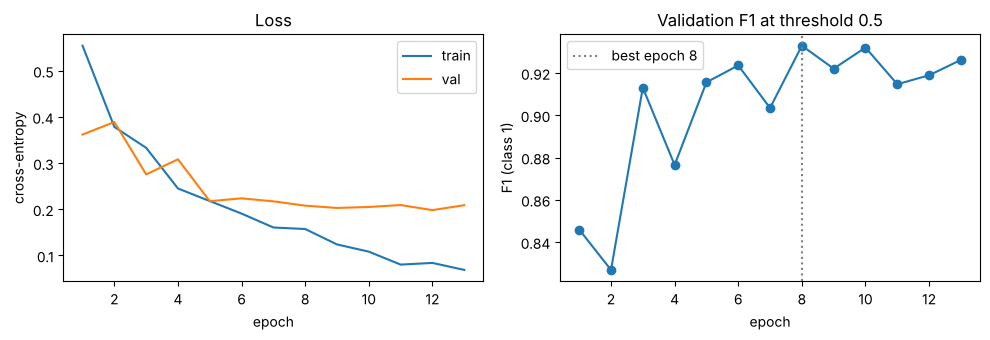

In [9]:
# save everything inference needs
(ART / "vocab.json").write_text(json.dumps(vocab.itos[2:], ensure_ascii=False))
model_cfg = {k: CFG[k] for k in ["max_len", "emb_dim", "num_filters", "kernel_sizes", "dropout"]}
model_cfg.update({"threshold": THRESHOLD, "best_epoch": best_epoch, "vocab_size": len(vocab),
                  "trainable_parameters": n_params, "seed": CFG["seed"]})
(ART / "config.json").write_text(json.dumps(model_cfg, indent=2))
log_df = pd.DataFrame(log); log_df.to_csv(ART / "training_log.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(log_df.epoch, log_df.train_loss, label="train"); ax[0].plot(log_df.epoch, log_df.val_loss, label="val")
ax[0].set(xlabel="epoch", ylabel="cross-entropy", title="Loss"); ax[0].legend()
ax[1].plot(log_df.epoch, log_df["val_f1@0.5"], marker="o"); ax[1].axvline(best_epoch, ls=":", c="gray", label=f"best epoch {best_epoch}")
ax[1].set(xlabel="epoch", ylabel="F1 (class 1)", title="Validation F1 at threshold 0.5"); ax[1].legend()
plt.tight_layout(); plt.show()

Training loss keeps falling while validation loss starts to rise after a few epochs: the model begins to overfit. Early stopping keeps the epoch with the best validation F1.

## 5. Evaluation on the test set (once)

All settings and the threshold are fixed by now. The test set is used here for the first and only time.

In [10]:
Xte, yte = encode_df(test_df)
test = test_df.copy()
test["prob"] = predict_proba(model, Xte).astype(np.float64)
test["pred"] = (test["prob"] >= THRESHOLD).astype(int)
test["domain"] = test["kazsandra_id"].str[:3].map(DOMAIN)

def scores(y, pred):
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[1], average=None, zero_division=0)
    return {"n": int(len(y)), "precision": float(p[0]), "recall": float(r[0]), "f1": float(f[0]),
            "accuracy": float(accuracy_score(y, pred))}

y, pred = test["label"].values, test["pred"].values
cm = confusion_matrix(y, pred, labels=[0, 1])
app = test[test["domain"] == "appstore"]
metrics = {"threshold": THRESHOLD, "profanity_class": scores(y, pred),
           "confusion_matrix": {"tn": int(cm[0, 0]), "fp": int(cm[0, 1]), "fn": int(cm[1, 0]), "tp": int(cm[1, 1])},
           "class_counts": {"0": int((y == 0).sum()), "1": int((y == 1).sum())},
           "appstore_only": scores(app["label"].values, app["pred"].values),
           "test_domains": test["domain"].value_counts().to_dict()}
Path("results").mkdir(exist_ok=True)
Path("results/test_metrics.json").write_text(json.dumps(metrics, indent=2))

pd.DataFrame({"full test set": metrics["profanity_class"], "app reviews only": metrics["appstore_only"]}).T.round(3)

,n,precision,recall,f1,accuracy
full test set,305.0,0.923,0.935,0.929,0.928
app reviews only,276.0,0.928,0.940,0.934,0.928


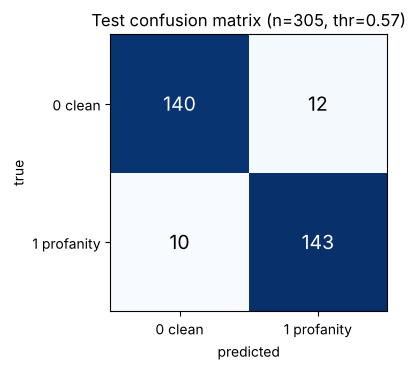

In [11]:
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["0 clean", "1 profanity"]); ax.set_yticks([0, 1], ["0 clean", "1 profanity"])
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Test confusion matrix (n={len(test)}, thr={THRESHOLD})")
fig.tight_layout(); fig.savefig("results/confusion_matrix.png", dpi=150); plt.show()

- **False positive:** a clean review is flagged. With automatic deletion, an honest (maybe negative) review disappears.
- **False negative:** a profane review stays visible to everyone.

For a marketplace, flagged comments are best sent to a human moderator rather than deleted automatically. Then false positives cost a few seconds of a moderator's time, and the threshold could be lowered to catch more profanity.

The app-review subset scores about the same as the full test set, so the model is not just learning "app review → profane".

### 5.1 Errors

In [12]:
test["error"] = np.where(test["pred"] == test["label"], "",
                         np.where(test["pred"] == 1, "false_positive", "false_negative"))
test[["kazsandra_id", "domain", "text", "label", "pred", "prob", "error"]].to_csv("results/test_predictions.csv", index=False)

for kind in ["false_positive", "false_negative"]:
    part = test[test["error"] == kind].sort_values("prob")
    print(f"\n{kind}: {len(part)}")
    for r in part.itertuples():
        print(f"  p={r.prob:.3f}  {r.text[:95]!r}")


false_positive: 12
  p=0.654  'Уау топ ффға ак таптым кидок есес екен'
  p=0.718  'жиги топ бірақ онлайн 😎🇰🇿😎🕋'
  p=0.783  'Айман йутуп не жазу мынау 🖓🖓'
  p=0.856  'Бр бәле боптго код келмей канд ішп код жахс ед'
  p=0.867  '💩💩💩💩💩👎👎👎👎👎 басында оинағанда вай фай ұстап тұрады норм болып сосын оиын дамытқансоң сет ұстап т'
  p=0.872  '2 бала'
  p=0.876  '10.0 10.0 10.0'
  p=0.892  'ал кеттик'
  p=0.916  'Объявления бере алмаисын куып калган.'
  p=0.937  'Жаман оинамаңдар'
  p=0.984  'Жақсы екен мен бұрын тйтанда жеңдімалендімен бір отадамдамын'
  p=0.996  'akbo*** екі шетінде галочка бар солармен озгертесиг'

false_negative: 10
  p=0.012  'Дәрігер [NAME] шынымен есек екен, не айтқанын өзі түсінбейді. Бүкіл қателіктерде үкіметті жаман'
  p=0.022  'Керек емес бок дуниелерди, биреудин жеке омирин акеп тыга берет. Анши,актерлердин асиресе'
  p=0.080  'өте күшті емес сука'
  p=0.156  'Өте қымбат болып кеттіңдер! Монополияға қарсы комитет біраз көттеріңнен айдауы керек секілді.'
  p=0.196  'Н

The main error patterns (analysed in detail in the README):

- `akbo***` (a masked login) is flagged: the model learned that `***` usually hides a swear word.
- very short clean comments (`10.0 10.0 10.0`, `2 бала`) are often flagged, because many short training comments are profane;
- the abbreviation `шшс` and insults like `мал` / `есек` inside otherwise normal sentences are missed: they are rare, and `мал` is also a neutral word, so the model needs context it does not have.

## 6. Predict on new comments

`ProfanityClassifier` loads only the saved files in `artifacts/` (weights, vocabulary, config with the threshold), so it works without retraining.

In [13]:
class ProfanityClassifier:
    def __init__(self, artifacts_dir="artifacts"):
        d = Path(artifacts_dir)
        self.cfg = json.loads((d / "config.json").read_text())
        self.vocab = Vocab(json.loads((d / "vocab.json").read_text()))
        self.model = CharCNN(len(self.vocab), self.cfg["emb_dim"], self.cfg["num_filters"],
                             tuple(self.cfg["kernel_sizes"]), self.cfg["dropout"])
        self.model.load_state_dict(torch.load(d / "model.pt", map_location="cpu", weights_only=True))
        self.model.eval()
        self.threshold = self.cfg["threshold"]

    @torch.no_grad()
    def predict(self, texts):
        ids = torch.tensor([self.vocab.encode(t, self.cfg["max_len"]) for t in texts], dtype=torch.long)
        probs = torch.softmax(self.model(ids), 1)[:, 1].tolist()
        return [(int(p >= self.threshold), round(p, 3)) for p in probs]

clf = ProfanityClassifier("artifacts")
demo = ["Тауар жақсы, маған ұнады", "Сапасы нашар, ақшама өкінемін", "Қотақбас екен", "к*т приложения екен"]
pd.DataFrame(clf.predict(demo), columns=["label", "p(profanity)"], index=demo)

,label,p(profanity)
"Тауар жақсы, маған ұнады",0,0.002
"Сапасы нашар, ақшама өкінемін",0,0.008
Қотақбас екен,1,1.000
к*т приложения екен,1,0.983


In [14]:
# Type your own comment here and run the cell
my_comment = "Тез жеткізді, рахмет!"
label, prob = clf.predict([my_comment])[0]
print(f"{'PROFANITY' if label else 'clean'}  (label {label}, p={prob}, threshold {clf.threshold})")

clean  (label 0, p=0.001, threshold 0.57)


## 7. Check: same result as the saved model

The run above writes `artifacts/` and `results/` again. With the pinned package versions the weights are identical to the ones committed to the repository; the cell below prints the main numbers for comparison with the README.

In [15]:
print(json.dumps({"best_epoch": best_epoch, "threshold": THRESHOLD, **{k: round(v, 4) for k, v in metrics["profanity_class"].items() if k != "n"},
                  "test_n": metrics["profanity_class"]["n"]}, indent=1))

{
 "best_epoch": 8,
 "threshold": 0.57,
 "precision": 0.9226,
 "recall": 0.9346,
 "f1": 0.9286,
 "accuracy": 0.9279,
 "test_n": 305
}
